# **AE complejo: objetivo del notebook**

Este notebook entrena un autoencoder convolucional para reconstruir imágenes faciales de `64x64` píxeles en escala de grises y estudia hasta qué punto puede generar imágenes nuevas. Primero se prepara un conjunto de entrenamiento y otro de validación; después se entrena el AE, se inspeccionan sus reconstrucciones, se muestrea el espacio latente y se calcula el FID de las imágenes generadas.

La diferencia clave es la siguiente: un AE aprende a reconstruir, pero no aprende explícitamente una distribución probabilística del latente. Por eso la fase de generación requiere comprobar si la aproximación `z ~ N(0, I)` es razonable para este modelo.


---

In [ ]:
%pip install "torchmetrics[image]"
%pip install opencv-python
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install tensorflow
%pip install pytorch

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

---

## **1. Carga de las imágenes**

In [ ]:
# El dataset contiene 30.000 imágenes numeradas de 0.jpg a 29999.jpg.
DATASET_DIR = "data/images"
IMG_SIZE = 64
TOTAL_IMAGES = 30000

# Reservamos el tensor en uint8 para no duplicar memoria antes de normalizar.
images = np.empty((TOTAL_IMAGES, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

In [ ]:
# Cargamos en escala de grises porque la submission usa un solo canal.
loaded_count = 0

for i in range(TOTAL_IMAGES):
    filename = f"{i}.jpg"
    filepath = os.path.join(DATASET_DIR, filename)
    
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise FileNotFoundError(f"No se pudo cargar la imagen: {filepath}")
    
    # Se conserva la resolución original cuando ya es 64x64; en otro caso se redimensiona (no debería darse).
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        
    images[i] = img
    loaded_count += 1

print(f"Total cargado: {loaded_count} imágenes")

Total cargado: 30000 imágenes


In [ ]:
# Verificamos forma, tipo y rango antes de normalizar para detectar datos corruptas.
print(f"Forma del tensor: {images.shape}")          # Esperado: (30000, 64, 64)
print(f"Tipo de dato:     {images.dtype}")          # Esperado: uint8
print(f"Valor mínimo:     {images.min()}")          # Esperado: 0 o cercano 
print(f"Valor máximo:     {images.max()}")          # Esperado: 255 o cercano 

Forma del tensor: (30000, 64, 64)
Tipo de dato:     uint8
Valor mínimo:     0
Valor máximo:     255


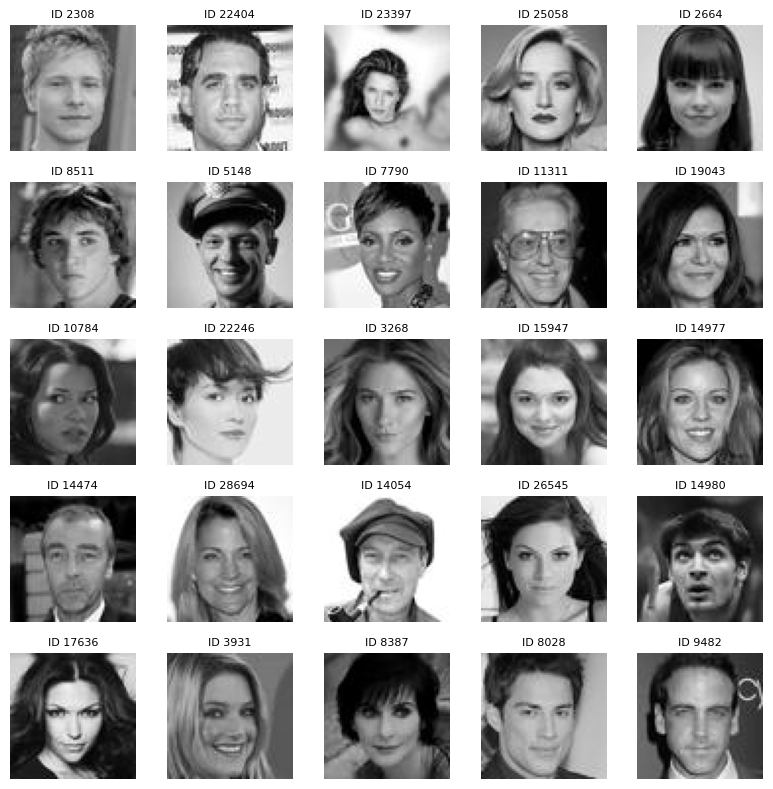

In [ ]:
# Visualización rápida
fig, axes = plt.subplots(5, 5, figsize=(8, 8))

# Esta semilla solo controla qué ejemplos se muestran, no el split ni el entrenamiento.
np.random.seed(42)
sample_indices = np.random.choice(TOTAL_IMAGES, size=25, replace=False)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"ID {idx}", fontsize=8)

plt.tight_layout()
plt.show()

---

## **2. Implementación del AE**

El modelo es un AE determinista formado por un encoder convolucional, un vector latente de 128 dimensiones y un decoder convolucional. El encoder comprime cada imagen de `64x64x1` hasta un mapa espacial de `4x4` y después hasta el vector `z`; el decoder realiza el recorrido inverso y produce una imagen en `[0, 1]` mediante una salida `sigmoid`.

La arquitectura no contiene un GMM, un VAE ni ningún segundo modelo generativo. Para que el muestreo normal estándar sea una aproximación razonable, el espacio latente se estandariza después de la capa `Dense` mediante `BatchNormalization(center=False, scale=False)`. Esta capa no añade desplazamiento ni escala: durante el entrenamiento centra y normaliza cada dimensión usando las estadísticas del batch, y durante inferencia usa las estadísticas acumuladas.


In [ ]:
# La misma semilla fija el split, el shuffle y las operaciones de TensorFlow.
SEED = 1234
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
# Normalizamos a [0,1] y separamos 27.000 imágenes para train y 3.000 para validación.
# La validación no se usa para actualizar pesos ni para generar la submission.

x_data = images.astype("float32") / 255.0
x_data = np.expand_dims(x_data, axis=-1)  # (30000, 64, 64, 1)

# La partición se realiza sobre índices para conservar la correspondencia con las imágenes originales.
val_size = int(0.10 * len(x_data))
# Se barajan índices
indices = np.random.permutation(len(x_data))
train_idx, val_idx = indices[val_size:], indices[:val_size]

x_train = x_data[train_idx]
x_val = x_data[val_idx]

print(f"Conjunto de entrenamiento: {x_train.shape}")
print(f"Conjunto de validación:    {x_val.shape}")

Conjunto de entrenamiento: (27000, 64, 64, 1)
Conjunto de validación:    (3000, 64, 64, 1)


In [ ]:
# Parámetros y encoder convolucional. El latente se estandariza antes de construir el decoder.
LATENT_DIM = 128
BATCH_SIZE = 128
EPOCHS = 60

encoder_inputs = keras.Input(
    shape=(IMG_SIZE, IMG_SIZE, 1),
    name="encoder_input"
)

# Cada convolución reduce la resolución a la mitad y aumenta la capacidad de representación.
x = layers.Conv2D(32, kernel_size=4, strides=2, padding="same", use_bias=False)(encoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(64, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(128, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(256, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

# La activación 4x4x256 contiene la representación espacial comprimida.
x = layers.Flatten()(x)

# Proyección final a 128 coordenadas latentes antes de la estandarización.
z = layers.Dense(
    LATENT_DIM,
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_vector"
)(x)

# Normalización sin centro ni escala: aproxima media 0 y varianza 1 por dimensión.
z = layers.BatchNormalization(
    center=False,
    scale=False,
    name="latent_standardization"
)(z)

encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")

In [ ]:
# Decoder independiente: recibe únicamente z y no necesita una imagen real ni skip connections.
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")

# Expandimos z al mapa espacial más pequeño del decoder.
x = layers.Dense(4 * 4 * 256, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 256))(x)

# Cada bloque duplica la resolución: 4 -> 8 -> 16 -> 32 -> 64.
for filters in (128, 64, 32, 16):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

# La última convolución produce una única intensidad por píxel en [0,1].
decoder_outputs = layers.Conv2D(
    1,
    kernel_size=3,
    padding="same",
    activation="sigmoid",
    name="decoder_output"
)(x)

decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")

In [ ]:
# Modelo completo para reconstrucción: imagen -> encoder -> z -> decoder -> imagen.
encoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1), name="autoencoder_input")
autoencoder = keras.Model(
    encoder_input,
    decoder_ae(encoder_ae(encoder_input)),
    name="autoencoder"
)

### **Decisiones de arquitectura**

- **Encoder convolucional:** cuatro bloques `Conv2D` con filtros `32, 64, 128 y 256` y `stride=2`. Cada bloque reduce la resolución espacial a la mitad: `64 -> 32 -> 16 -> 8 -> 4`, mientras aumenta el número de canales y captura patrones progresivamente más abstractos.

- **Normalización interna:** `BatchNormalization` y `LeakyReLU` estabilizan el entrenamiento y permiten mantener gradientes útiles incluso cuando algunas activaciones son negativas.

- **Espacio latente:** la activación `4x4x256` se aplana y pasa a una `Dense` de `128` dimensiones con regularización L2.

- **Estandarización del latente:** después de la `Dense` se aplica `BatchNormalization(center=False, scale=False)`. El objetivo es que cada dimensión tenga aproximadamente media cero y varianza uno, sin una transformación  aprendible; así `N(0, I)` es una aproximación más coherente para generar. Si esto no se hace, el resultado es que el muestreo normal estándar (generación posterior)produce imágenes borrosas y poco realistas, ya que los números desde los que generamos tienen una distribución muy diferente a la deseada. Habría que aplicar un segundo modelo como un GMM para aprender la distribución del latente.

- **Decoder:** proyecta el vector latente `z` mediante una capa `Dense` hasta un mapa `4x4x256`. Después, cuatro bloques formados por `UpSampling2D` bilineal y `Conv2D` duplican progresivamente la resolución: `4 -> 8 -> 16 -> 32 -> 64`. Se utiliza interpolación bilineal seguida de convolución en lugar de `Conv2DTranspose` para que no haya problemas de solapamiento. `Conv2DTranspose` intenta aprender cómo agrandar la imagen y cómo rellenar los nuevos píxeles al mismo tiempo. Si el tamaño del filtro no es divisible exactamente por el stride, algunas zonas de la imagen reconstruida reciben más superposiciones de datos que otras, generando píxeles brillantes y oscuros alternados, especialmente visible en bordes. Con la interpolación bilineal la imagen se agranda con un promediado suave y uniforme, y la convolución posterior refina los detalles.

- **Salida:** una convolución final con `sigmoid` produce intensidades en `[0, 1]`, que luego se convierten a `[0, 255]` para la submission.


In [ ]:
# Pérdida combinada: L1 para precisión de píxel y SSIM para estructura local.
# Se calcula por batch y se promedian los términos.
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    ssim = 1.0 - tf.reduce_mean(
        tf.image.ssim(y_true, y_pred, max_val=1.0)
    )
    return 0.5 * l1 + 0.5 * ssim


# Adam ajusta todos los pesos del encoder y decoder.
autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=ssim_l1_loss
)


def make_dataset(x_array, training=True):
    dataset = tf.data.Dataset.from_tensor_slices((x_array, x_array))
    # Solo train recibe shuffle y flip; validation permanece determinista.
    # Estamos haciendo data augmentation solo en el conjunto de entrenamiento para mejorar la generalización.
    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(x_array), 10000),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        dataset = dataset.map(
            lambda image, target: (
                tf.image.random_flip_left_right(image),
                target
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )
        # Entrada y objetivo son la misma imagen volteada: el AE aprende invariancia al flip.
        dataset = dataset.map(
            lambda image, _: (image, image),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(x_train, training=True)
val_ds = make_dataset(x_val, training=False)

callbacks = [
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-5,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

history_ae = autoencoder.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=callbacks
)

Epoch 1/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 41s 181ms/step - loss: 0.3546 - val_loss: 0.4788 - learning_rate: 0.0010
Epoch 2/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 36s 171ms/step - loss: 0.2517 - val_loss: 0.3320 - learning_rate: 0.0010
Epoch 3/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 37s 174ms/step - loss: 0.2246 - val_loss: 0.2129 - learning_rate: 0.0010
Epoch 4/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 38s 178ms/step - loss: 0.2089 - val_loss: 0.2004 - learning_rate: 0.0010
Epoch 5/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 42s 199ms/step - loss: 0.1980 - val_loss: 0.2099 - learning_rate: 0.0010
Epoch 6/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 45s 211ms/step - loss: 0.1914 - val_loss: 0.1961 - learning_rate: 0.0010
Epoch 7/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 45s 212ms/step - loss: 0.1860 - val_loss: 0.1804 - learning_rate: 0.0010
Epoch 8/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 47s 221ms/step - loss: 0.1800 - val_loss: 0.1770 - learning_rate: 0.0010
Epoch 9/60
211/211 ━━━━━━━━━━━━━━━━━━━━ 48s 227ms/step - loss: 0.1758 - val_loss: 0.1761 - learn

### **Decisiones de pérdida y entrenamiento**

La pérdida es la media de dos objetivos complementarios:

- **L1:** penaliza el error absoluto por píxel y tiende a conservar bordes sin sobrerreaccionar a errores aislados (evitamos el MSE).
- **SSIM:** compara estructura local, luminancia y contraste; ayuda a que las reconstrucciones mantengan la estructura aunque no coincidan exactamente en cada píxel.

Ambos términos tienen peso `0.5`. El `RandomFlip` horizontal se aplica únicamente al conjunto de entrenamiento y la imagen volteada se usa también como objetivo, de forma que la transformación no introduce un objetivo inconsistente. La validación no se aumenta ni se baraja con transformaciones. `ReduceLROnPlateau` reduce la tasa de aprendizaje si `val_loss` deja de mejorar y `EarlyStopping` restaura los mejores pesos.


---

## **3. Resultados del entrenamiento**

Las siguientes celdas muestran la evolución de la pérdida y el comportamiento de las reconstrucciones. En la ejecución guardada, la mejor época según `val_loss` fue la `58`, con pérdida `0.1370` en entrenamiento y `0.1365` en validación. La proximidad entre ambas cifras sugiere que no hay una separación grande entre el ajuste al train y el rendimiento sobre validación.


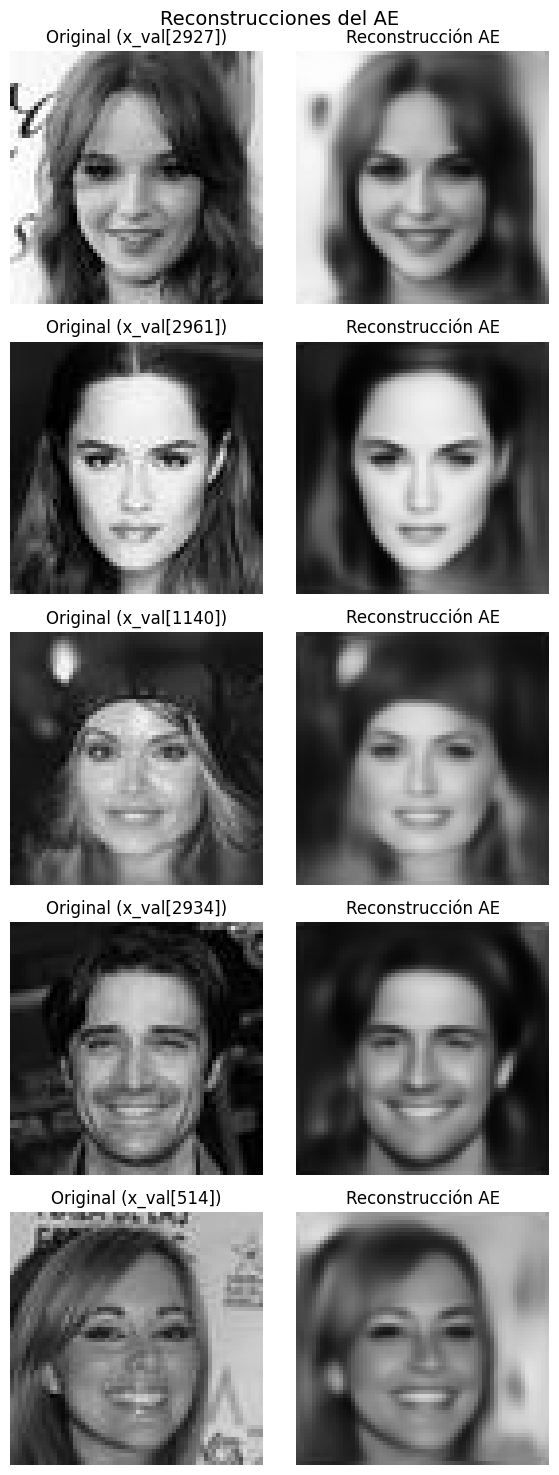

In [ ]:
# Evaluación sobre validación: estas imágenes no se usan para entrenar ni generar la submission.
COMPARISON_SEED = SEED
comparison_rng = np.random.default_rng(COMPARISON_SEED)
# Seleccionamos ejemplos no repetidos de validación.
comparison_indices = comparison_rng.choice(len(x_val), size=5, replace=False)
x_val_samples = x_val[comparison_indices]

ae_reconstructions = autoencoder.predict(x_val_samples, verbose=0)

fig, axes = plt.subplots(5, 2, figsize=(6, 15))
fig.suptitle("Reconstrucciones del AE", fontsize=14)

for row, (original, reconstruction, sample_index) in enumerate(
    zip(x_val_samples, ae_reconstructions, comparison_indices)
):
    axes[row, 0].imshow(original[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Original (x_val[{sample_index}])")
    axes[row, 1].imshow(reconstruction[..., 0], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title("Reconstrucción AE")
    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Resumen de la mejor epoch según la pérdida de validación.
metrics_history = history_ae.history
best_epoch = int(np.argmin(metrics_history["val_loss"]))

print(f"Mejor época según val_loss: {best_epoch + 1}")
print(f"Train loss:      {metrics_history['loss'][best_epoch]:.4f}")
print(f"Validation loss: {metrics_history['val_loss'][best_epoch]:.4f}")

Mejor época según val_loss: 58
Train loss:      0.1370
Validation loss: 0.1365


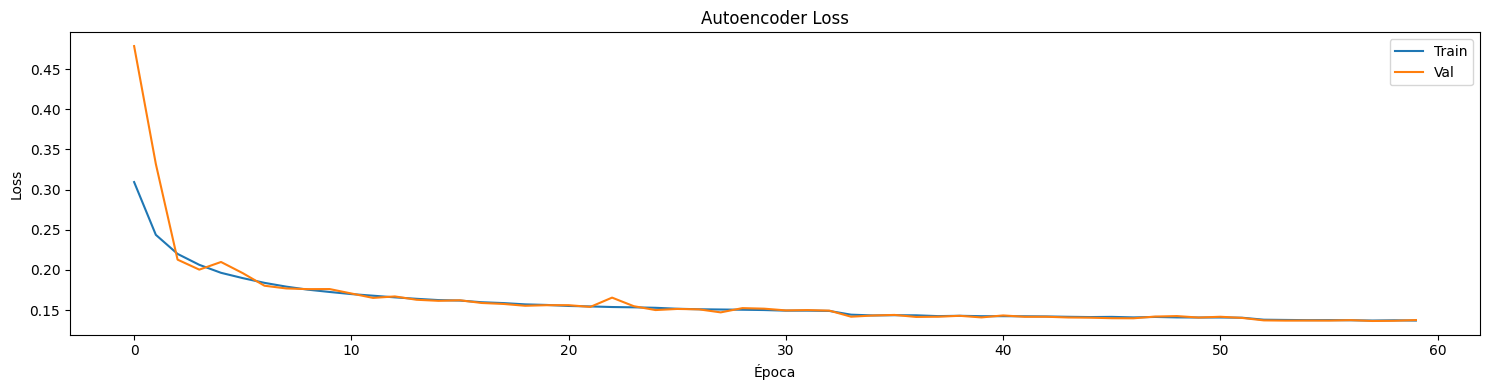

In [ ]:
# Curvas para detectar convergencia y posible overfitting.
fig, axes = plt.subplots(1, figsize=(15, 4))

axes.plot(history_ae.history["loss"], label="Train")
axes.plot(history_ae.history["val_loss"], label="Val")
axes.set_title("Autoencoder Loss")
axes.set_xlabel("Época")
axes.set_ylabel("Loss")
axes.legend()

plt.tight_layout()
plt.show()

---

## **4. Generación y creación de la submission**

El decoder se utiliza como único modelo generativo. Se generan `200` vectores latentes con una normal estándar y se decodifican directamente:

```text
z ~ N(0, I) -> decoder_ae -> imagen
```

La estandarización del espacio latente hace que esta elección sea más defendible que en un AE sin normalización, pero no convierte al AE en un modelo probabilístico perfecto: las correlaciones, la geometría global y la distribución del latente siguen siendo aproximaciones. Por eso el diagnóstico posterior compara las estadísticas de `z_train`, el FID de varias escalas de ruido y el FID de las reconstrucciones.

Las imágenes de validación no se usan para generar la submission. Solo se emplean para evaluación y como referencia real del FID.


In [ ]:
# Número de filas para la submission.
N_SAMPLES = 200
SAMPLE_SEED = 1234

sample_rng = np.random.default_rng(SAMPLE_SEED)
z_samples_ae = sample_rng.normal(
    loc=0.0,
    scale=1.0,
    size=(N_SAMPLES, LATENT_DIM)
).astype(np.float32)

print(f"Muestras latentes generadas: {z_samples_ae.shape}")

Muestras latentes generadas: (200, 128)


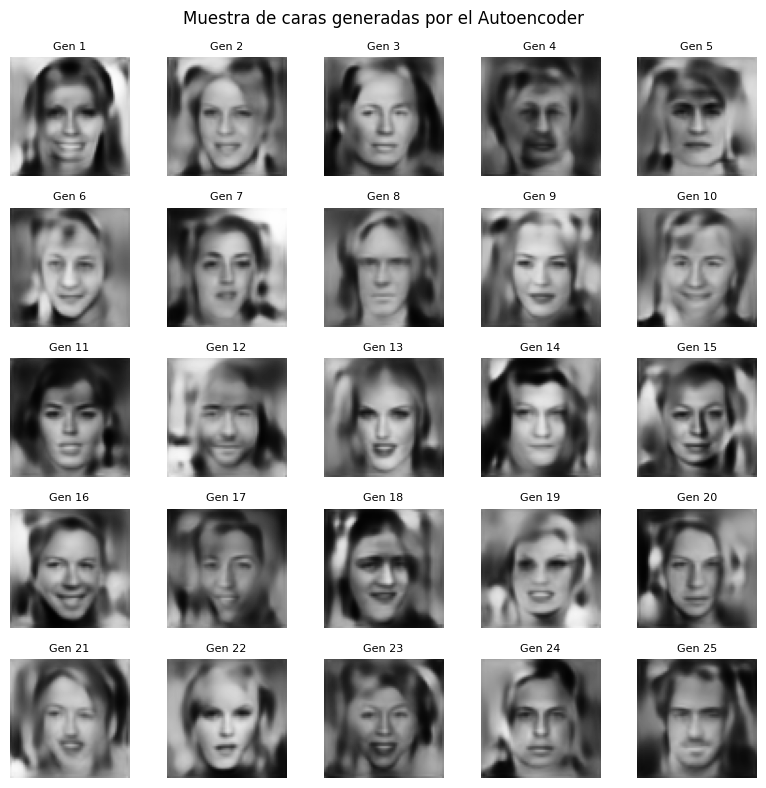

In [ ]:
# El decoder devuelve float32 en [0, 1]; aquí se modifica para visualizar en [0, 255].
generated_float = decoder_ae.predict(
    z_samples_ae,
    batch_size=N_SAMPLES,
    verbose=0
)
generated_imgs = np.clip(
    np.round(generated_float * 255.0), 0, 255
).astype(np.uint8)
generated_imgs = np.squeeze(generated_imgs, axis=-1)

assert generated_float.shape == (N_SAMPLES, IMG_SIZE, IMG_SIZE, 1)
assert np.isfinite(generated_float).all()
assert generated_float.min() >= 0.0 and generated_float.max() <= 1.0

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
fig.suptitle("Muestra de caras generadas por el Autoencoder", fontsize=12)
for i, ax in enumerate(axes.flat):
    ax.imshow(generated_imgs[i], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"Gen {i + 1}", fontsize=8)
plt.tight_layout()
plt.show()


In [ ]:
# Exportación: solo estas 200 imágenes generadas se pasan al formato de entrega.
flat_pixels = generated_imgs.reshape(N_SAMPLES, IMG_SIZE * IMG_SIZE)
df_submission = pd.DataFrame(
    flat_pixels,
    columns=[str(i) for i in range(IMG_SIZE * IMG_SIZE)]
)
df_submission.insert(0, "Usage", "Public")
df_submission.insert(0, "ID", range(1, N_SAMPLES + 1))

assert df_submission.shape == (N_SAMPLES, 2 + IMG_SIZE * IMG_SIZE)
assert df_submission.isnull().sum().sum() == 0
assert df_submission.iloc[:, 2:].values.min() >= 0
assert df_submission.iloc[:, 2:].values.max() <= 255
assert list(df_submission.columns[:3]) == ["ID", "Usage", "0"]

csv_filename = "submission_ae_complex.csv"
df_submission.to_csv(csv_filename, index=False)
print(f"Archivo guardado como '{csv_filename}' | forma: {df_submission.shape}")


Archivo guardado como 'submission_ae_complex.csv' | forma: (200, 4098)


---

## **5. Evaluación FID del AE**

El FID compara las distribuciones de características de Inception entre imágenes reales e imágenes generadas. Para que el número sea comparable con los otros notebooks, la referencia real es `x_val`, se usan `512` imágenes, se convierten las imágenes grayscale a `uint8`, se replica el canal gris a RGB y `feature=2048`.

En la ejecución guardada, el muestreo estándar produjo `FID = 111.7476`. Este valor no debe interpretarse como una pérdida de entrenamiento ni como una prueba de que cada imagen sea válida: resume una diferencia estadística entre dos conjuntos de características. Las reconstrucciones sirven como techo aproximado de la capacidad de reconstrucción, mientras que el FID de muestras normales evalúa además si el muestreo elegido cubre el espacio latente.


In [ ]:
FID_SEED = SEED
FID_BATCH_SIZE = 64
# Limitamos a 512 para mantener el coste controlado y usar el mismo protocolo comparativo.
FID_NUM_IMAGES = min(len(x_val), 512)

device = "cpu"

def prepare_images_for_fid(images):
    images = np.asarray(images)
    
    # Si la imagen ya es uint8, asumimos que está en [0, 255] y no la tocamos
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
        
    # Asegurar que tenga dimensión de canal (por si viene en 3D: N, H, W)
    if images.ndim == 3:
        images = images[..., np.newaxis]
        
    images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(images)


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    # Inception convierte cada imagen en un vector de características; FID compara sus medias/covarianzas.
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(device)
    real_images = prepare_images_for_fid(real_images)
    generated_images = prepare_images_for_fid(generated_images)

    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(device), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(device), real=False)
        return fid.compute().item()


# Referencia real: únicamente validación; las muestras generadas proceden de z~N(0,I).
real_images = x_val[:FID_NUM_IMAGES]
fid_rng = np.random.default_rng(FID_SEED)
z_fid = fid_rng.normal(
    0.0, 1.0, size=(FID_NUM_IMAGES, LATENT_DIM)
).astype(np.float32)
generated_ae_fid = decoder_ae.predict(
    z_fid,
    batch_size=FID_BATCH_SIZE,
    verbose=0
)

fid_ae = calculate_fid(
    generated_ae_fid,
    real_images,
    batch_size=FID_BATCH_SIZE
)
print(f"FID AE ({FID_NUM_IMAGES} imágenes, dispositivo={device}): {fid_ae:.4f}")


FID AE (512 imágenes, dispositivo=cpu): 111.7476


---

## **6. ¿Qué aporta la estandarización del latente?**

Un AE convencional tiene este recorrido:

$$x \longrightarrow 	ext{Encoder} \longrightarrow z \longrightarrow 	ext{Decoder} \longrightarrow \hat{x}$$

pero no impone por sí mismo que los códigos `z` sigan una normal estándar. Si las coordenadas tienen desplazamientos o escalas diferentes, muestrear `N(0, I)` puede producir muchos vectores fuera de las regiones donde el decoder fue entrenado.

Lo que muestran los resultados a continuación:

- media absoluta media por dimensión: `0.042`;
- desviación estándar mínima/mediana/máxima: `0.978 / 0.992 / 1.011`;
- correlación absoluta media entre dimensiones: `0.060`;
- `E[||z||²] = 126.5`, frente a `128` para `N(0, I)` en 128 dimensiones.

Estas cifras indican que la aproximación es razonable: las escalas están cerca de uno, las medias son pequeñas y las correlaciones son bajas. No obstante, la normalización por batch no garantiza independencia completa ni convierte el AE en un VAE; por eso el FID sigue siendo una comprobación experimental necesaria.

El resultado principal guardado fue `FID = 111.7476` para `tau=1` en el muestreo estándar. Al reducir la escala del ruido se obtuvieron, como referencia, `123.1801` (`tau=0.5`), `114.6863` (`tau=0.7`), `110.7221` (`tau=0.85`) y `109.8950` (`tau=1.0`). La comparación debería hacerse siempre con la misma referencia, mismo número de imágenes y preprocesado.


In [ ]:
z_train = encoder_ae.predict(x_train, batch_size=256, verbose=0)
std = z_train.std(0)
corr = np.corrcoef(z_train.T)
off = corr[~np.eye(LATENT_DIM, dtype=bool)]
print(f"|media| por dim: {np.abs(z_train.mean(0)).mean():.3f} (N(0,I): 0)")
print(f"std por dim  min/mediana/max: {std.min():.3f} / {np.median(std):.3f} / {std.max():.3f} (N(0,I): 1)")
print(f"|corr| media entre dims: {np.abs(off).mean():.3f} (N(0,I): 0)")
print(f"E||z||^2: {(z_train**2).sum(1).mean():.1f} (N(0,I): {LATENT_DIM})")

rng = np.random.default_rng(SEED)
# Para comparar N(0,I) con una gaussiana ajustada.
z_diag = rng.multivariate_normal(z_train.mean(0), np.cov(z_train.T), size=512).astype(np.float32)
print("FID gaussiana ajustada:", calculate_fid(decoder_ae.predict(z_diag, verbose=0), real_images))

# Techo aproximado de reconstrucción
idx = rng.choice(len(x_train), 512, replace=False)
print("FID reconstrucciones  :", calculate_fid(autoencoder.predict(x_train[idx], verbose=0), real_images))

# Sensibilidad del FID a la escala del ruido normal, manteniendo la misma referencia.
for tau in (0.5, 0.7, 0.85, 1.0):
    z = tau * rng.normal(size=(512, LATENT_DIM)).astype(np.float32)
    print(f"tau={tau}:", calculate_fid(decoder_ae.predict(z, verbose=0), real_images))

|media| por dim: 0.042 (N(0,I): 0)
std por dim  min/mediana/max: 0.978 / 0.992 / 1.011 (N(0,I): 1)
|corr| media entre dims: 0.060 (N(0,I): 0)
E||z||^2: 126.5 (N(0,I): 128)
FID gaussiana ajustada: 103.81461334228516
FID reconstrucciones  : 86.92765808105469
tau=0.5: 123.18009185791016
tau=0.7: 114.68632507324219
tau=0.85: 110.72209167480469
tau=1.0: 109.89503479003906


In [57]:
# Guardar los modelos para poder reutilizar el AE y su decoder.
os.makedirs("checkpoints", exist_ok=True)
autoencoder.save("checkpoints/ae_complex.keras")
encoder_ae.save("checkpoints/encoder_complex.keras")
decoder_ae.save("checkpoints/decoder_complex.keras")
print("Modelos guardados en checkpoints/")

Modelos guardados en checkpoints/
